Degree : 1
r2_score of training data: 0.3657241273794126
r2_score of testing data: 0.23335039815872138


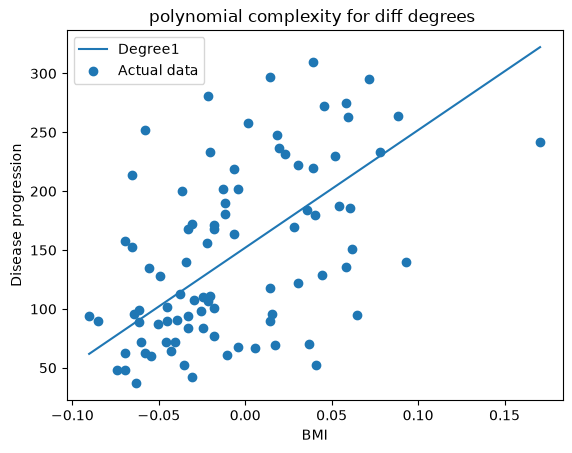

Degree : 2
r2_score of training data: 0.36651069841284856
r2_score of testing data: 0.2289715971205667


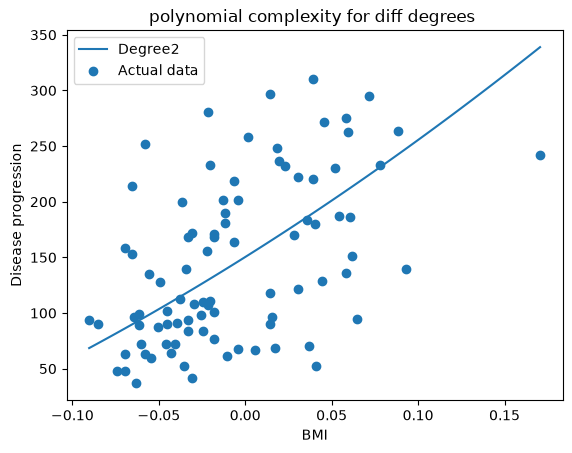

Degree : 3
r2_score of training data: 0.36665649129084266
r2_score of testing data: 0.23285636640090268


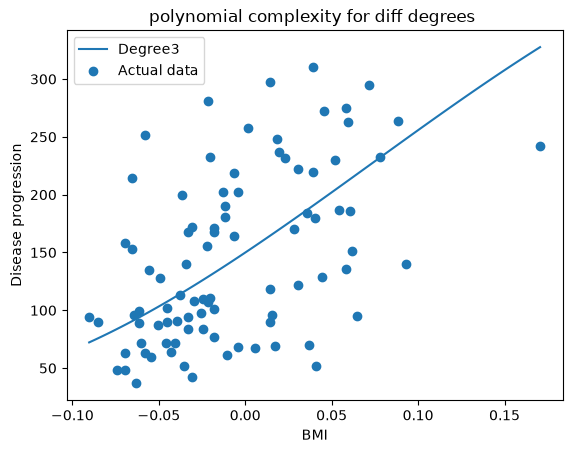

Degree : 4
r2_score of training data: 0.36951838895759503
r2_score of testing data: 0.20233600732379786


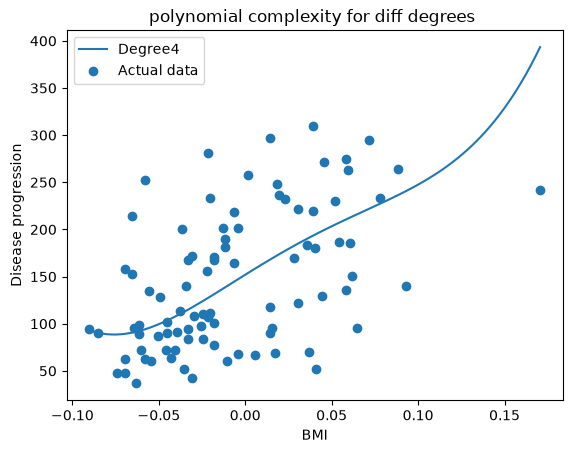

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import r2_score
from sklearn.datasets import load_diabetes

data = load_diabetes()
X = data.data[:,[2]]
y = data.target
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

for degree in (1,2,3,4):
    poly = PolynomialFeatures(degree = degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly,y_train)
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)
    print("Degree :" ,degree)
    print("r2_score of training data:" , r2_score(y_train, train_pred))
    print("r2_score of testing data:" , r2_score(y_test, test_pred))

    X_plot = np.linspace(X.min(),X.max(),100).reshape(-1,1)
    y_plot = model.predict(poly.transform(X_plot))
    plt.plot(X_plot,y_plot,label = 'Degree' + str(degree))
    plt.scatter(X_test,y_test,label = "Actual data")
    plt.xlabel("BMI")
    plt.ylabel("Disease progression")
    plt.title("polynomial complexity for diff degrees ")
    plt.legend()
    plt.show()